In [82]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# "$NH_3$"

Tri atómy H v rovine $z=0$ tvoria rovnoramenný trojuholník a N je nad (alebo pod) jeho ťažiskom.

Pre jednodocuhosť uvažujme iba pohyb N v ose $z$ a fixné H-H vzdialenosti $a = 1$

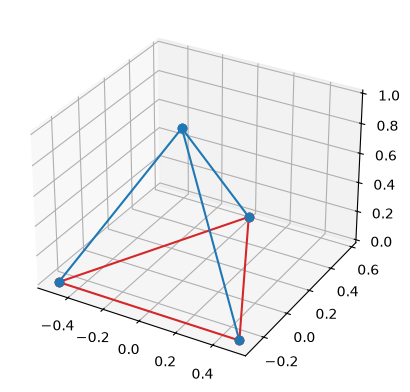

In [83]:
# "pruzinova" konstanta medzi N a H
k = 1

# polohy vodikov
H1 = np.array([0.5, -np.sqrt(3)/6 ,0])
H2 = np.array([-0.5, -np.sqrt(3)/6, 0])
H3 = np.array([0, np.sqrt(3)/3, 0])

vodiky = [H1, H2, H3]

# Tazisko je v (0, 0, 0)
T = (H1 + H2 + H3)/3

#poloha N
N = np.array([0, 0, 1])

fig = plt.figure()
ax = fig.add_subplot(projection="3d")
ax.plot(*np.stack((H1, H2), axis=1), "-o", color="tab:red")
ax.plot(*np.stack((H2, H3), axis=1), "-o", color="tab:red")
ax.plot(*np.stack((H3, H1), axis=1), "-o", color="tab:red")

ax.plot(*np.stack((H1, N), axis=1), "-o", color="tab:blue")
ax.plot(*np.stack((H2, N), axis=1), "-o", color="tab:blue")
ax.plot(*np.stack((H3, N), axis=1), "-o", color="tab:blue")

## Potencial v ose $z$

Pre polohu dusiku $(0, 0, z)$ sčítame všetky $\frac{1}{2} k (r_{NH} - r_0)^2$ kde $r_0$ je rovnovážna vzdialenosť N-H

Pre rovnovážnu H-H vzdialenosť $a$ je rovnovážna vzdialenosť N od roviny v ktorej sú H
$$ h = \pm \sqrt{r_0^2 - \frac{a^2}{3}} $$
ak je výraz v odmocnine reálny, inak existuje iba jedno globálne minimum v $h=0$.

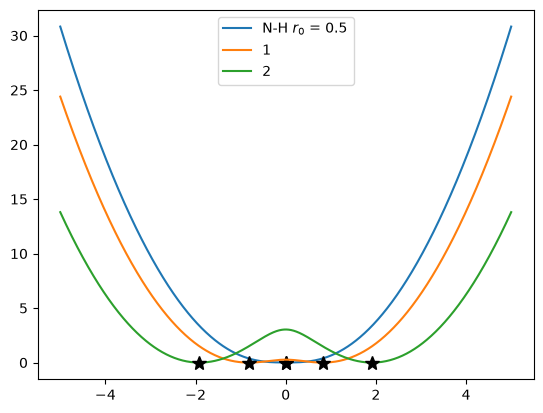

In [84]:
# potencial v ose z
def potencial(z, r0=2):
    # poloha dusiku
    _z = np.atleast_1d(z)
    N = np.zeros((len(_z), 3))
    N[:,2] = _z

    V = 0
    for H in vodiky:
        # spojnice s vodikmi
        r = N - H
        V += (np.linalg.norm(r, axis=-1) - r0)**2
    V *= 0.5*k
    return V

def hmin(r0, a=1):
    x = r0**2 - a**2/3
    if x > 0:
        x = np.sqrt(x)
        return (-x, x)
    else:
        return (0, 0)

zs = np.linspace(-5, 5, 1000)

fig, ax = plt.subplots()
ax.plot(zs, potencial(zs, r0=0.5), label="N-H $r_0$ = 0.5")
ax.plot(hmin(r0=0.5), [0, 0], "*", color="k", ms=10)

ax.plot(zs, potencial(zs, r0=1), label="1")
ax.plot(hmin(r0=1), [0, 0], "*", color="k", ms=10)

ax.plot(zs, potencial(zs, r0=2), label="2")
ax.plot(hmin(r0=2), [0, 0], "*", color="k", ms=10)
ax.legend(loc="best")

## Trajektória v závislosti na energií $E$

Uvažujme počiatočnú podmienku v dolnom minime s energiou $E$, t.j.
$$ z(t = 0) = - \sqrt{r_0^2 - \frac{a^2}{3}}. $$
V minime je potencial $V = 0$ kvôli tomu, ako sme ho definovali, takže
$$ \dot z(t =0 ) = +\sqrt{\frac{2E}{m}} $$

A uvažujme $r_0 > a/\sqrt{3}$ aby sme mali dve minimá

In [ ]:
def sila(_t, zvz, r0): # t sa nepouziva, treba ho tam len pre solve_ivp()
    # poloha a rychlost dusiku v ose z
    z, vz = zvz

    N = np.array([0, 0, z])

    F = np.zeros(3)
    for H in vodiky:
        # spojnice s vodikmi
        r = N - H
        r0_vec = r/np.linalg.norm(r)*r0
        F += -k*(r - r0_vec)
    return vz, F[2] # chceme iba F_z

def pocatecne_podminky(E, r0, m=1):
    return hmin(r0)[0], np.sqrt(2*E/m)

Text(0, 0.5, '$z(t)$')

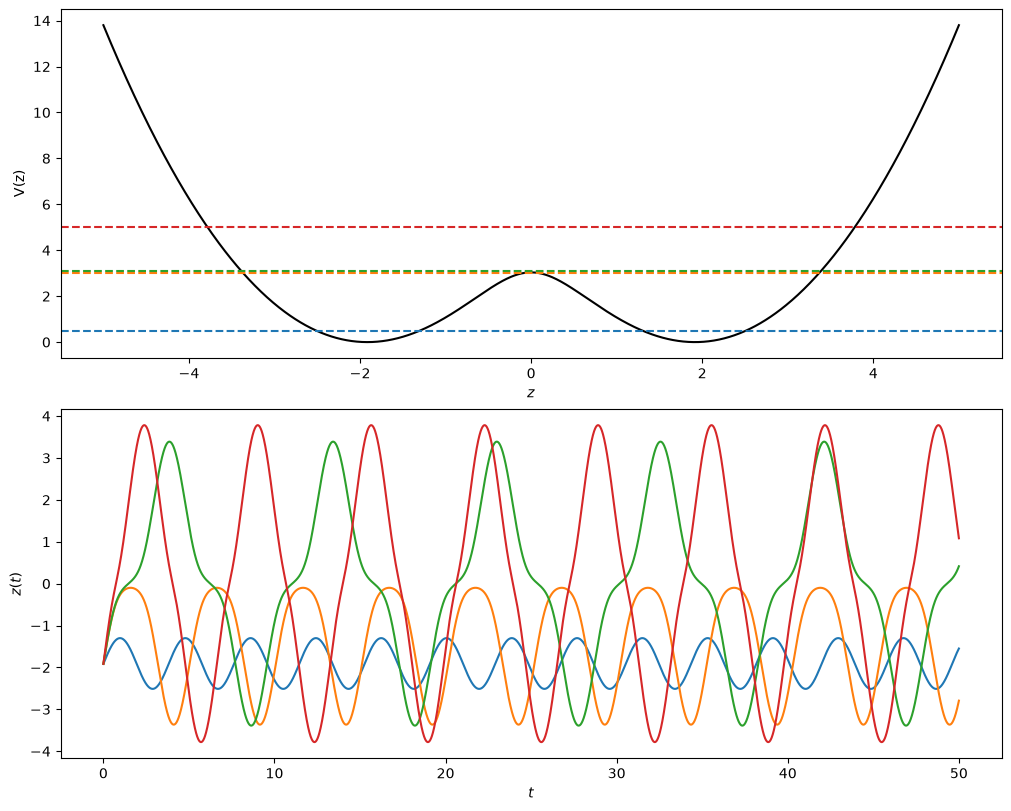

In [86]:
fig, ax = plt.subplots(2, 1, figsize=(10, 8),layout="constrained")

r0 = 2

#Energie
Es = [0.5, 3.0, 3.1, 5]

ax[0].plot(zs, potencial(zs, r0=r0), "-", color="k")

for E in Es:
    sol = solve_ivp(sila, y0=pocatecne_podminky(E, r0=2), t_span=(0, 50), args=(2,), max_step=1e-2)
    l = ax[1].plot(sol.t, sol.y[0,:])
    ax[0].axhline(E, ls="--", color=l[-1].get_color())

ax[0].set_xlabel("$z$")
ax[0].set_ylabel("V(z)")

ax[1].set_xlabel("$t$")
ax[1].set_ylabel("$z(t)$")